In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
# ==========================================================
# Handwritten English Character Recognition using CNN
# ==========================================================


# Import Libraries

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

warnings.filterwarnings("ignore")

print("TensorFlow Version :", tf.__version__)

TensorFlow Version : 2.20.0


In [3]:
# ==========================================================
# Check GPU
# ==========================================================

gpus = tf.config.list_physical_devices('GPU')

if len(gpus) > 0:
    print("GPU is Available")
    print(gpus)
else:
    print("GPU is NOT Available")

GPU is Available
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [4]:
# ==========================================================
# Dataset Path
# ==========================================================

train_path = "/kaggle/input/datasets/rahulkumar1822/character-dataset/combined_folder/train"

test_path = "/kaggle/input/datasets/rahulkumar1822/character-dataset/combined_folder/test"

In [5]:
# ==========================================================
# Verify Dataset
# ==========================================================

print("Train Exists :", os.path.exists(train_path))
print("Test Exists :", os.path.exists(test_path))

Train Exists : True
Test Exists : True


In [6]:
# ==========================================================
# Check Number of Classes
# ==========================================================

print("Train Classes :", len(os.listdir(train_path)))
print("Test Classes  :", len(os.listdir(test_path)))

Train Classes : 52
Test Classes  : 52


In [7]:
import os

classes_name = sorted([
    folder
    for folder in os.listdir(train_path)
    if os.path.isdir(os.path.join(train_path, folder))
])

NUM_CLASSES = len(classes_name)

print("Number of Classes:", NUM_CLASSES)

Number of Classes: 52


In [8]:
# ==========================================================
# Count Images in Each Class
# ==========================================================

image_count = {}

for cls in classes_name:

    folder = os.path.join(train_path, cls)

    images = [
        img
        for img in os.listdir(folder)
        if img.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    image_count[cls] = len(images)

dataset_info = pd.DataFrame({
    "Class": list(image_count.keys()),
    "Images": list(image_count.values())
})

dataset_info

,Class,Images
0,A_caps,44
1,B_caps,44
2,C_caps,44
3,D_caps,44
4,E_caps,44
5,F_caps,44
6,G_caps,44
7,H_caps,44
8,I_caps,44
9,J_caps,44


In [9]:
# ==========================================================
# Dataset Statistics
# ==========================================================

print("Total Images   :", dataset_info["Images"].sum())

print("Average Images :", dataset_info["Images"].mean())

print("Maximum Images :", dataset_info["Images"].max())

print("Minimum Images :", dataset_info["Images"].min())

Total Images   : 2288
Average Images : 44.0
Maximum Images : 44
Minimum Images : 44


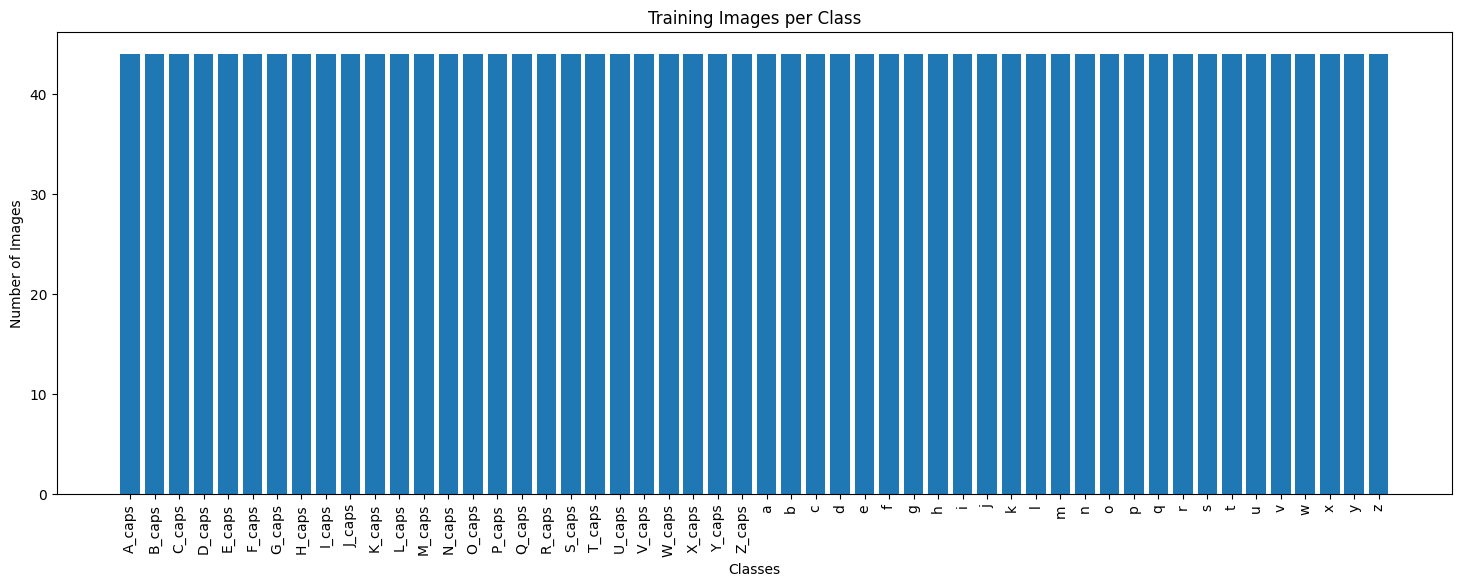

In [10]:
# ==========================================================
# Plot Class Distribution
# ==========================================================

plt.figure(figsize=(18,6))

plt.bar(dataset_info["Class"], dataset_info["Images"])

plt.xlabel("Classes")

plt.ylabel("Number of Images")

plt.title("Training Images per Class")

plt.xticks(rotation=90)

plt.show()

In [11]:
# ==========================================================
# Dataset Parameters
# ==========================================================

IMAGE_SIZE = (28,28)

BATCH_SIZE = 32

SEED = 42

In [12]:
# ==========================================================
# Load Training Dataset
# ==========================================================

train_dataset = tf.keras.utils.image_dataset_from_directory(

    directory=train_path,

    labels="inferred",

    label_mode="int",

    validation_split=0.20,

    subset="training",

    seed=SEED,

    image_size=IMAGE_SIZE,

    color_mode="grayscale",

    batch_size=BATCH_SIZE,

    shuffle=True

)

Found 2288 files belonging to 52 classes.
Using 1831 files for training.


I0000 00:00:1785742057.494667      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1785742057.497444      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [13]:
# ==========================================================
# Validation Dataset
# ==========================================================

validation_dataset = tf.keras.utils.image_dataset_from_directory(

    directory=train_path,

    labels="inferred",

    label_mode="int",

    validation_split=0.20,

    subset="validation",

    seed=SEED,

    image_size=IMAGE_SIZE,

    color_mode="grayscale",

    batch_size=BATCH_SIZE,

    shuffle=True

)

Found 2288 files belonging to 52 classes.
Using 457 files for validation.


In [14]:
# ==========================================================
# Load Test Dataset
# ==========================================================

test_dataset = tf.keras.utils.image_dataset_from_directory(

    directory=test_path,

    labels="inferred",

    label_mode="int",

    image_size=IMAGE_SIZE,

    color_mode="grayscale",

    batch_size=BATCH_SIZE,

    shuffle=False

)

Found 572 files belonging to 52 classes.


In [15]:
# ==========================================================
# Dataset Summary
# ==========================================================

print("Training Batches   :", len(train_dataset))
print("Validation Batches :", len(validation_dataset))
print("Testing Batches    :", len(test_dataset))

print("Number of Classes  :", len(classes_name))

Training Batches   : 58
Validation Batches : 15
Testing Batches    : 18
Number of Classes  : 52


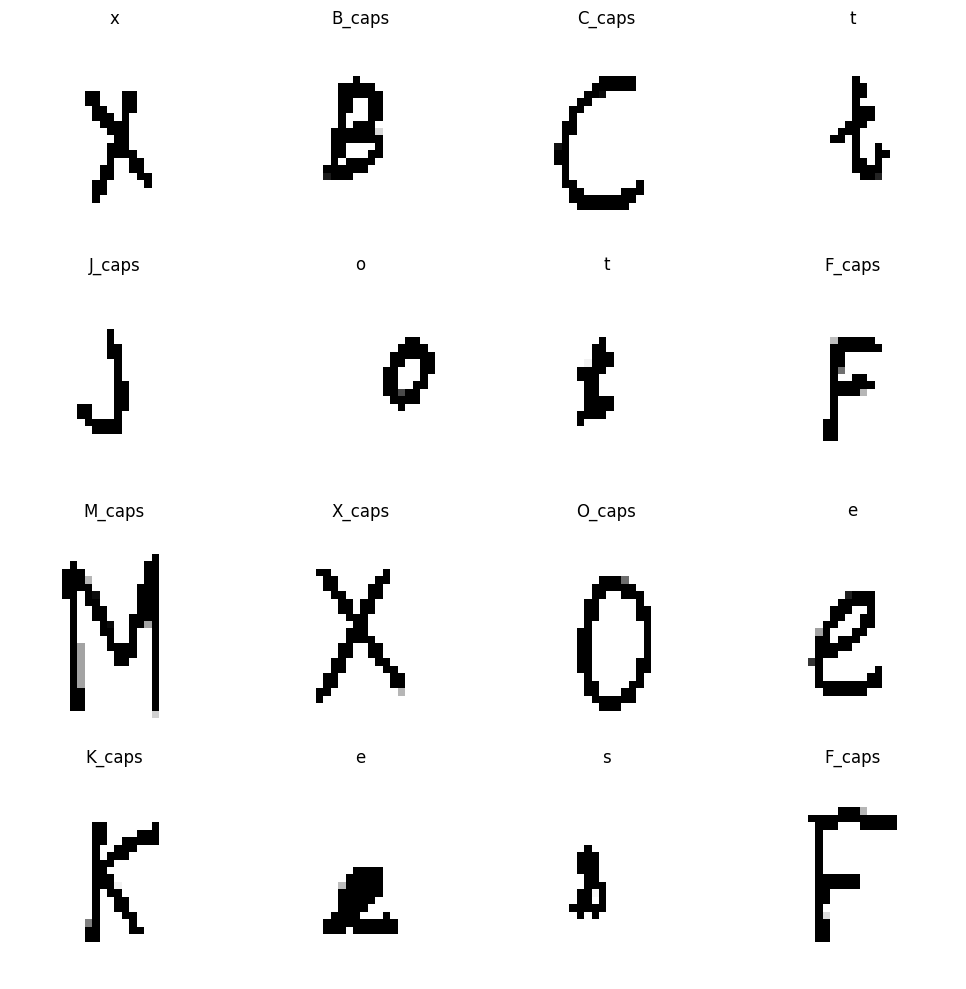

In [16]:
# ==========================================================
# Display Sample Images
# ==========================================================

plt.figure(figsize=(10,10))

for images, labels in train_dataset.take(1):

    for i in range(min(16, len(images))):

        plt.subplot(4,4,i+1)

        plt.imshow(images[i].numpy().squeeze(), cmap="gray")

        plt.title(classes_name[int(labels[i])])

        plt.axis("off")

plt.tight_layout()

plt.show()

In [17]:
# ==========================================================
# Image Shape
# ==========================================================

for images, labels in train_dataset.take(1):

    print("Images Shape :", images.shape)

    print("Labels Shape :", labels.shape)

Images Shape : (32, 28, 28, 1)
Labels Shape : (32,)


In [18]:
#================================================
#To verify images come from different folders
#================================================

for images, labels in train_dataset.take(1):

    print("Labels:")
    print(labels.numpy())

Labels:
[28  4 48  5 27 50 21 12 35 43 26 42 17 25  1 11 29 43 25 45 42 43 38 44
 15 29 40  7 17 51 10 28]


In [19]:
#=====================================
# print the corresponding class names
#=====================================

for images, labels in train_dataset.take(1):

    print("Classes in this batch:")

    for label in labels.numpy():
        print(classes_name[label])

Classes in this batch:
l
l
G_caps
R_caps
E_caps
t
o
h
t
J_caps
c
p
g
L_caps
e
t
k
l
q
a
t
G_caps
r
i
t
H_caps
q
b
p
F_caps
C_caps
L_caps


In [20]:
# ==========================================================
# Pixel Value Range
# ==========================================================

for images, labels in train_dataset.take(1):

    print("Minimum Pixel :", tf.reduce_min(images).numpy())

    print("Maximum Pixel :", tf.reduce_max(images).numpy())

Minimum Pixel : 0.0
Maximum Pixel : 255.0


In [21]:
# ==========================================================
# Normalize Images
# ==========================================================

# Normalize pixel values from [0,255] to [0,1]
normalization_layer = tf.keras.layers.Rescaling(1.0 / 255)

AUTOTUNE = tf.data.AUTOTUNE

# Training Dataset

train_dataset = train_dataset.map(
    lambda images, labels: (normalization_layer(images), labels),
    num_parallel_calls=AUTOTUNE
)

# Validation Dataset

validation_dataset = validation_dataset.map(
    lambda images, labels: (normalization_layer(images), labels),
    num_parallel_calls=AUTOTUNE
)

# Test Dataset

test_dataset = test_dataset.map(
    lambda images, labels: (normalization_layer(images), labels),
    num_parallel_calls=AUTOTUNE
)

# ==========================================================
# Improve Dataset Performance
# ==========================================================

train_dataset = (
    train_dataset
    .cache()
    .shuffle(buffer_size=1000, seed=SEED)
    .prefetch(AUTOTUNE)
)

validation_dataset = (
    validation_dataset
    .cache()
    .prefetch(AUTOTUNE)
)

test_dataset = (
    test_dataset
    .cache()
    .prefetch(AUTOTUNE)
)

In [22]:
# ==========================================================
# Verify Pixel Range
# ==========================================================

for images, labels in train_dataset.take(1):

    print("Minimum Pixel :", tf.reduce_min(images).numpy())

    print("Maximum Pixel :", tf.reduce_max(images).numpy())

Minimum Pixel : 0.0
Maximum Pixel : 1.0


In [23]:
# ==========================================================
# Data Augmentation Layer
# ==========================================================

data_augmentation = tf.keras.Sequential(

    [

        tf.keras.layers.RandomRotation(
            factor=0.05,
            fill_mode="nearest"
        ),

        tf.keras.layers.RandomZoom(
            height_factor=0.05,
            width_factor=0.05,
            fill_mode="nearest"
        ),

        tf.keras.layers.RandomTranslation(
            height_factor=0.05,
            width_factor=0.05,
            fill_mode="nearest"
        ),

    ],

    name="Data_Augmentation"

)

In [23]:
# ==================================
# CNN Model
# ==================================

from tensorflow.keras import regularizers

model = tf.keras.Sequential([

    # ======================================================
    # Input Layer
    # ======================================================
    tf.keras.layers.Input(shape=(28, 28, 1)),

    # ======================================================
    # Data Augmentation
    # ======================================================
    data_augmentation,

    # ======================================================
    # Block 1
    # ======================================================
    tf.keras.layers.Conv2D(
        32,
        (3,3),
        padding="same",
        use_bias=False,
        kernel_regularizer=regularizers.l2(1e-4)
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),

    tf.keras.layers.Conv2D(
        32,
        (3,3),
        padding="same",
        use_bias=False,
        kernel_regularizer=regularizers.l2(1e-4)
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),

    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Dropout(0.25),

    # ======================================================
    # Block 2
    # ======================================================
    tf.keras.layers.Conv2D(
        64,
        (3,3),
        padding="same",
        use_bias=False,
        kernel_regularizer=regularizers.l2(1e-4)
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),

    tf.keras.layers.Conv2D(
        64,
        (3,3),
        padding="same",
        use_bias=False,
        kernel_regularizer=regularizers.l2(1e-4)
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),

    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Dropout(0.30),

    # ======================================================
    # Block 3
    # ======================================================
    tf.keras.layers.Conv2D(
        128,
        (3,3),
        padding="same",
        use_bias=False,
        kernel_regularizer=regularizers.l2(1e-4)
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),

    tf.keras.layers.Conv2D(
        128,
        (3,3),
        padding="same",
        use_bias=False,
        kernel_regularizer=regularizers.l2(1e-4)
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),

    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Dropout(0.35),

    # ======================================================
    # Block 4
    # ======================================================
    tf.keras.layers.Conv2D(
        256,
        (3,3),
        padding="same",
        use_bias=False,
        kernel_regularizer=regularizers.l2(1e-4)
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),

    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Dropout(0.40),

    # ======================================================
    # Classification Head
    # ======================================================
    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=regularizers.l2(1e-4)
    ),

    tf.keras.layers.Dropout(0.50),

    tf.keras.layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(1e-4)
    ),

    tf.keras.layers.Dropout(0.30),

    # ======================================================
    # Output Layer
    # ======================================================
    tf.keras.layers.Dense(
        52,
        activation="softmax"
    )

])

In [24]:
# ==========================================================
# CNN Model
# ==========================================================

from tensorflow.keras import regularizers

model = tf.keras.Sequential([

    # ======================================================
    # Input Layer
    # ======================================================
    tf.keras.layers.Input(shape=(28, 28, 1)),

    # ======================================================
    # Data Augmentation
    # ======================================================
    data_augmentation,

    # ======================================================
    # Block 1
    # ======================================================
    tf.keras.layers.Conv2D(
        32,
        (3, 3),
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal",
        kernel_regularizer=regularizers.l2(1e-4)
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),

    tf.keras.layers.Conv2D(
        32,
        (3, 3),
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal",
        kernel_regularizer=regularizers.l2(1e-4)
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),

    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.20),

    # ======================================================
    # Block 2
    # ======================================================
    tf.keras.layers.Conv2D(
        64,
        (3, 3),
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal",
        kernel_regularizer=regularizers.l2(1e-4)
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),

    tf.keras.layers.Conv2D(
        64,
        (3, 3),
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal",
        kernel_regularizer=regularizers.l2(1e-4)
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),

    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.25),

    # ======================================================
    # Block 3
    # ======================================================
    tf.keras.layers.Conv2D(
        128,
        (3, 3),
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal",
        kernel_regularizer=regularizers.l2(1e-4)
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),

    tf.keras.layers.Conv2D(
        128,
        (3, 3),
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal",
        kernel_regularizer=regularizers.l2(1e-4)
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),

    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.30),

    # ======================================================
    # Block 4
    # ======================================================
    tf.keras.layers.Conv2D(
        256,
        (3, 3),
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal",
        kernel_regularizer=regularizers.l2(1e-4)
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),

    tf.keras.layers.Conv2D(
        256,
        (3, 3),
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal",
        kernel_regularizer=regularizers.l2(1e-4)
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),

    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.35),

    # ======================================================
    # Classification Head
    # ======================================================
    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(
        256,
        activation="relu",
        kernel_initializer="he_normal",
        kernel_regularizer=regularizers.l2(1e-4)
    ),

    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.40),

    tf.keras.layers.Dense(
        128,
        activation="relu",
        kernel_initializer="he_normal",
        kernel_regularizer=regularizers.l2(1e-4)
    ),

    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.25),

    # ======================================================
    # Output Layer
    # ======================================================
    tf.keras.layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )

])

In [25]:
# ==========================================================
# Compile CNN
# ==========================================================

optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-3
)

model.compile(

    optimizer=optimizer,

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")
    ]

)

In [26]:
# ==========================================================
# Display Model Configuration
# ==========================================================

print("=" * 60)

print("Optimizer      :", optimizer.__class__.__name__)

print("Learning Rate  :", float(optimizer.learning_rate.numpy()))

print("Loss Function  : SparseCategoricalCrossentropy")

print("Metric         : SparseCategoricalAccuracy")

print("=" * 60)

Optimizer      : Adam
Learning Rate  : 0.0010000000474974513
Loss Function  : SparseCategoricalCrossentropy
Metric         : SparseCategoricalAccuracy


In [27]:
# ==========================================================
# Display Model Architecture
# ==========================================================

# Display model summary
model.summary()

# Save model architecture as an image
tf.keras.utils.plot_model(

    model,

    to_file="cnn_model_architecture.png",

    show_shapes=True,

    show_dtype=True,

    show_layer_names=True,

    expand_nested=True,

    dpi=150

)

print("Model architecture saved as 'cnn_model_architecture.png'")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Data_Augmentation (Sequential)  │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 7, 7, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 1,281,492 (4.89 MB)

 Trainable params: 1,278,804 (4.88 MB)

 Non-trainable params: 2,688 (10.50 KB)

Model architecture saved as 'cnn_model_architecture.png'




In [28]:
# Display

from IPython.display import Image

Image("cnn_model_architecture.png")

In [29]:
# ==========================================================
# Model Parameters Summary
# ==========================================================

# Total parameters
total_params = model.count_params()

# Trainable parameters
trainable_params = sum(
    tf.keras.backend.count_params(w)
    for w in model.trainable_weights
)

# Non-trainable parameters
non_trainable_params = sum(
    tf.keras.backend.count_params(w)
    for w in model.non_trainable_weights
)

print("=" * 60)
print("Model Parameters Summary")
print("=" * 60)

print(f"Total Parameters        : {total_params:,}")
print(f"Trainable Parameters    : {trainable_params:,}")
print(f"Non-Trainable Parameters: {non_trainable_params:,}")

print("=" * 60)

Model Parameters Summary
Total Parameters        : 1,281,492
Trainable Parameters    : 1,278,804
Non-Trainable Parameters: 2,688


In [30]:
# ==========================================================
# Check Model Status
# ==========================================================

print("=" * 60)

print("Model Built Status :", model.built)

if model.built:
    print("Model is ready for training.")
else:
    print("Model has not been built yet.")

print("=" * 60)

Model Built Status : True
Model is ready for training.


In [31]:
# ==========================================================
# Import Callbacks
# ==========================================================

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# ==========================================================
# Save Best Model
# ==========================================================

checkpoint = ModelCheckpoint(

    filepath="/kaggle/working/best_character_model.keras",

    monitor="val_accuracy",

    mode="max",

    save_best_only=True,

    save_weights_only=False,

    verbose=1

)
# ==========================================================
# Early Stopping
# ==========================================================

early_stopping = EarlyStopping(

    monitor="val_accuracy",

    mode="max",

    patience=10,

    restore_best_weights=True,

    verbose=1

)

# ==========================================================
# Reduce Learning Rate
# ==========================================================

reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    mode="min",

    factor=0.5,

    patience=3,

    cooldown=1,

    min_delta=1e-4,

    min_lr=1e-6,

    verbose=1

)

# ==========================================================
# Callback List
# ==========================================================

callbacks = [

    checkpoint,

    early_stopping,

    reduce_lr

]

print("=" * 60)
print("Callbacks Configured Successfully")
print("=" * 60)
print("1. ModelCheckpoint")
print("   Monitor        : val_accuracy")
print("   Save Best Only : True")
print()
print("2. EarlyStopping")
print("   Monitor        : val_accuracy")
print("   Patience       : 8")
print("   Restore Best   : True")
print()
print("3. ReduceLROnPlateau")
print("   Monitor        : val_loss")
print("   Factor         : 0.5")
print("   Patience       : 3")
print("   Minimum LR     : 1e-6")
print("=" * 60)

Callbacks Configured Successfully
1. ModelCheckpoint
   Monitor        : val_accuracy
   Save Best Only : True

2. EarlyStopping
   Monitor        : val_accuracy
   Patience       : 8
   Restore Best   : True

3. ReduceLROnPlateau
   Monitor        : val_loss
   Factor         : 0.5
   Patience       : 3
   Minimum LR     : 1e-6


In [45]:
# ==========================================================
# Train CNN Model
# ==========================================================

EPOCHS = 100

history = model.fit(

    train_dataset,

    validation_data=validation_dataset,

    epochs=EPOCHS,

    callbacks=callbacks,

    verbose=1

)

Epoch 1/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.0644 - loss: 4.2204
Epoch 1: val_accuracy improved from 0.07440 to 0.08096, saving model to /kaggle/working/best_character_model.keras

Epoch 1: finished saving model to /kaggle/working/best_character_model.keras
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.0628 - loss: 4.1934 - val_accuracy: 0.0810 - val_loss: 3.8964 - learning_rate: 1.2500e-04
Epoch 2/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0523 - loss: 4.1933
Epoch 2: val_accuracy improved from 0.08096 to 0.08753, saving model to /kaggle/working/best_character_model.keras

Epoch 2: finished saving model to /kaggle/working/best_character_model.keras
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.0519 - loss: 4.1779 - val_accuracy: 0.0875 - val_loss: 3.8695 - learning_rate: 1.2500e-04
Epoch 3/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0628 - loss: 4.0911
Epoch 3: val_accuracy did not improve from 0.08753
58/58 ━━━━━━━━━━━

In [46]:
# ==========================================================
# Save Best Model
# ==========================================================

MODEL_PATH = "/kaggle/working/best_character_model.keras"

if model.built:
    model.save(MODEL_PATH)

    print("=" * 60)
    print("Best model saved successfully!")
    print(f"Model File : {MODEL_PATH}")
    print("=" * 60)
else:
    print("Model has not been built. Train the model before saving.")

Best model saved successfully!
Model File : /kaggle/working/best_character_model.keras


In [47]:
# ==========================================================
# Training History
# ==========================================================

print("=" * 60)
print("Training History")
print("=" * 60)

print("Available Metrics:")
print(list(history.history.keys()))

print("\nTraining Completed Epochs :", len(history.history["loss"]))

print(f"Final Training Accuracy   : {history.history['accuracy'][-1]:.4f}")
print(f"Final Validation Accuracy : {history.history['val_accuracy'][-1]:.4f}")

print(f"Final Training Loss       : {history.history['loss'][-1]:.4f}")
print(f"Final Validation Loss     : {history.history['val_loss'][-1]:.4f}")

print(f"Best Validation Accuracy  : {max(history.history['val_accuracy']):.4f}")

print("=" * 60)

Training History
Available Metrics:
['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate']

Training Completed Epochs : 36
Final Training Accuracy   : 0.1262
Final Validation Accuracy : 0.1269
Final Training Loss       : 3.5888
Final Validation Loss     : 3.5591
Best Validation Accuracy  : 0.1422


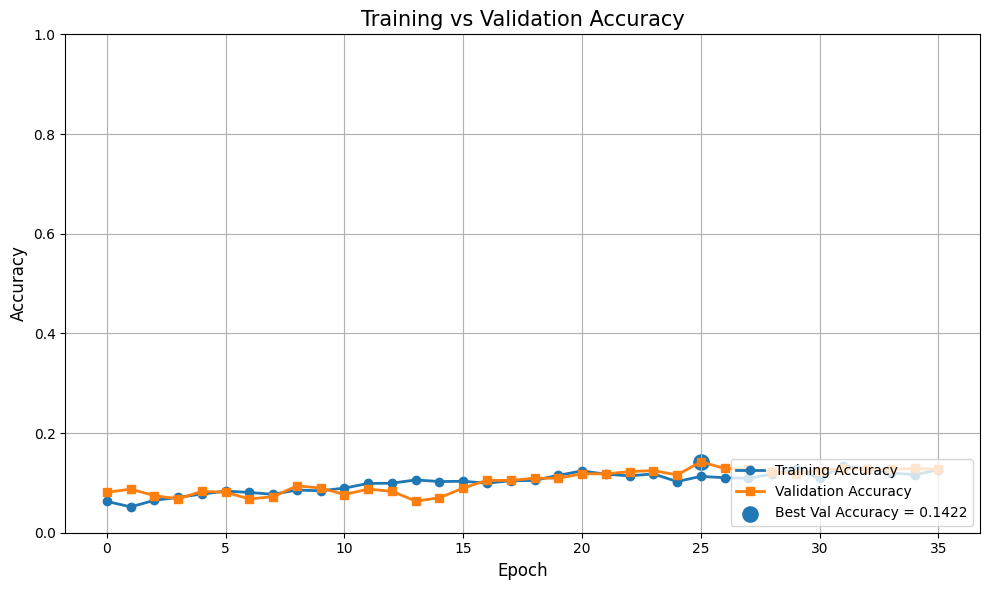

In [48]:
# ==========================================================
# Accuracy Curve
# ==========================================================

plt.figure(figsize=(10,6))

plt.plot(

    history.history["accuracy"],

    marker="o",

    linewidth=2,

    label="Training Accuracy"

)

plt.plot(

    history.history["val_accuracy"],

    marker="s",

    linewidth=2,

    label="Validation Accuracy"

)

best_epoch = np.argmax(history.history["val_accuracy"])

best_accuracy = history.history["val_accuracy"][best_epoch]

plt.scatter(

    best_epoch,

    best_accuracy,

    s=120,

    label=f"Best Val Accuracy = {best_accuracy:.4f}"

)

plt.title("Training vs Validation Accuracy", fontsize=15)

plt.xlabel("Epoch", fontsize=12)

plt.ylabel("Accuracy", fontsize=12)

plt.ylim(0,1)

plt.grid(True)

plt.legend(loc="lower right")

plt.tight_layout()

plt.show()

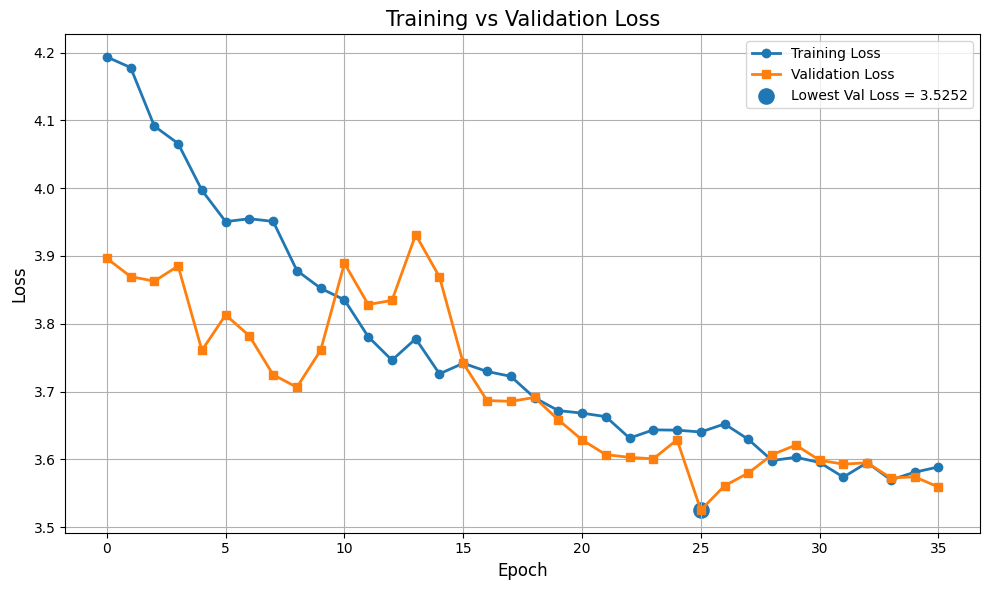

In [49]:
# ==========================================================
# Loss Curve
# ==========================================================

plt.figure(figsize=(10,6))

plt.plot(

    history.history["loss"],

    marker="o",

    linewidth=2,

    label="Training Loss"

)

plt.plot(

    history.history["val_loss"],

    marker="s",

    linewidth=2,

    label="Validation Loss"

)

best_epoch = np.argmin(history.history["val_loss"])

best_loss = history.history["val_loss"][best_epoch]

plt.scatter(

    best_epoch,

    best_loss,

    s=120,

    label=f"Lowest Val Loss = {best_loss:.4f}"

)

plt.title("Training vs Validation Loss", fontsize=15)

plt.xlabel("Epoch", fontsize=12)

plt.ylabel("Loss", fontsize=12)

plt.grid(True)

plt.legend(loc="upper right")

plt.tight_layout()

plt.show()

In [50]:
# ==========================================================
# Import Required Libraries
# ==========================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ==========================================================
# Predict Test Dataset
# ==========================================================

# Predict probabilities
predictions = model.predict(
    test_dataset,
    verbose=1
)

# Convert probabilities to class labels
predicted_labels = np.argmax(predictions, axis=1)

# Collect true labels
true_labels = np.concatenate(
    [labels.numpy() for _, labels in test_dataset]
)

print("=" * 60)
print("Prediction Summary")
print("=" * 60)

print("Prediction Shape :", predictions.shape)
print("Predicted Labels :", predicted_labels.shape)
print("True Labels      :", true_labels.shape)

print("=" * 60)

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Prediction Summary
Prediction Shape : (572, 52)
Predicted Labels : (572,)
True Labels      : (572,)


In [51]:
# ==========================================================
# Classification Report
# ==========================================================

from sklearn.metrics import (
    accuracy_score,
    classification_report
)

# Calculate Overall Accuracy
test_accuracy = accuracy_score(
    true_labels,
    predicted_labels
)

print("=" * 70)
print("MODEL PERFORMANCE")
print("=" * 70)

print(f"Overall Test Accuracy : {test_accuracy * 100:.2f}%")

print("\nClassification Report:\n")

print(
    classification_report(
        true_labels,
        predicted_labels,
        target_names=classes_name,
        digits=4,
        zero_division=0
    )
)

print("=" * 70)

MODEL PERFORMANCE
Overall Test Accuracy : 12.94%

Classification Report:

              precision    recall  f1-score   support

      A_caps     0.3333    0.3636    0.3478        11
      B_caps     0.2500    0.0909    0.1333        11
      C_caps     0.1111    0.6364    0.1892        11
      D_caps     0.0333    0.0909    0.0488        11
      E_caps     0.0000    0.0000    0.0000        11
      F_caps     0.0000    0.0000    0.0000        11
      G_caps     0.0000    0.0000    0.0000        11
      H_caps     0.0000    0.0000    0.0000        11
      I_caps     0.0000    0.0000    0.0000        11
      J_caps     0.4286    0.2727    0.3333        11
      K_caps     0.0000    0.0000    0.0000        11
      L_caps     0.2083    0.4545    0.2857        11
      M_caps     0.0000    0.0000    0.0000        11
      N_caps     0.0000    0.0000    0.0000        11
      O_caps     0.6000    0.2727    0.3750        11
      P_caps     0.0000    0.0000    0.0000        11
      Q

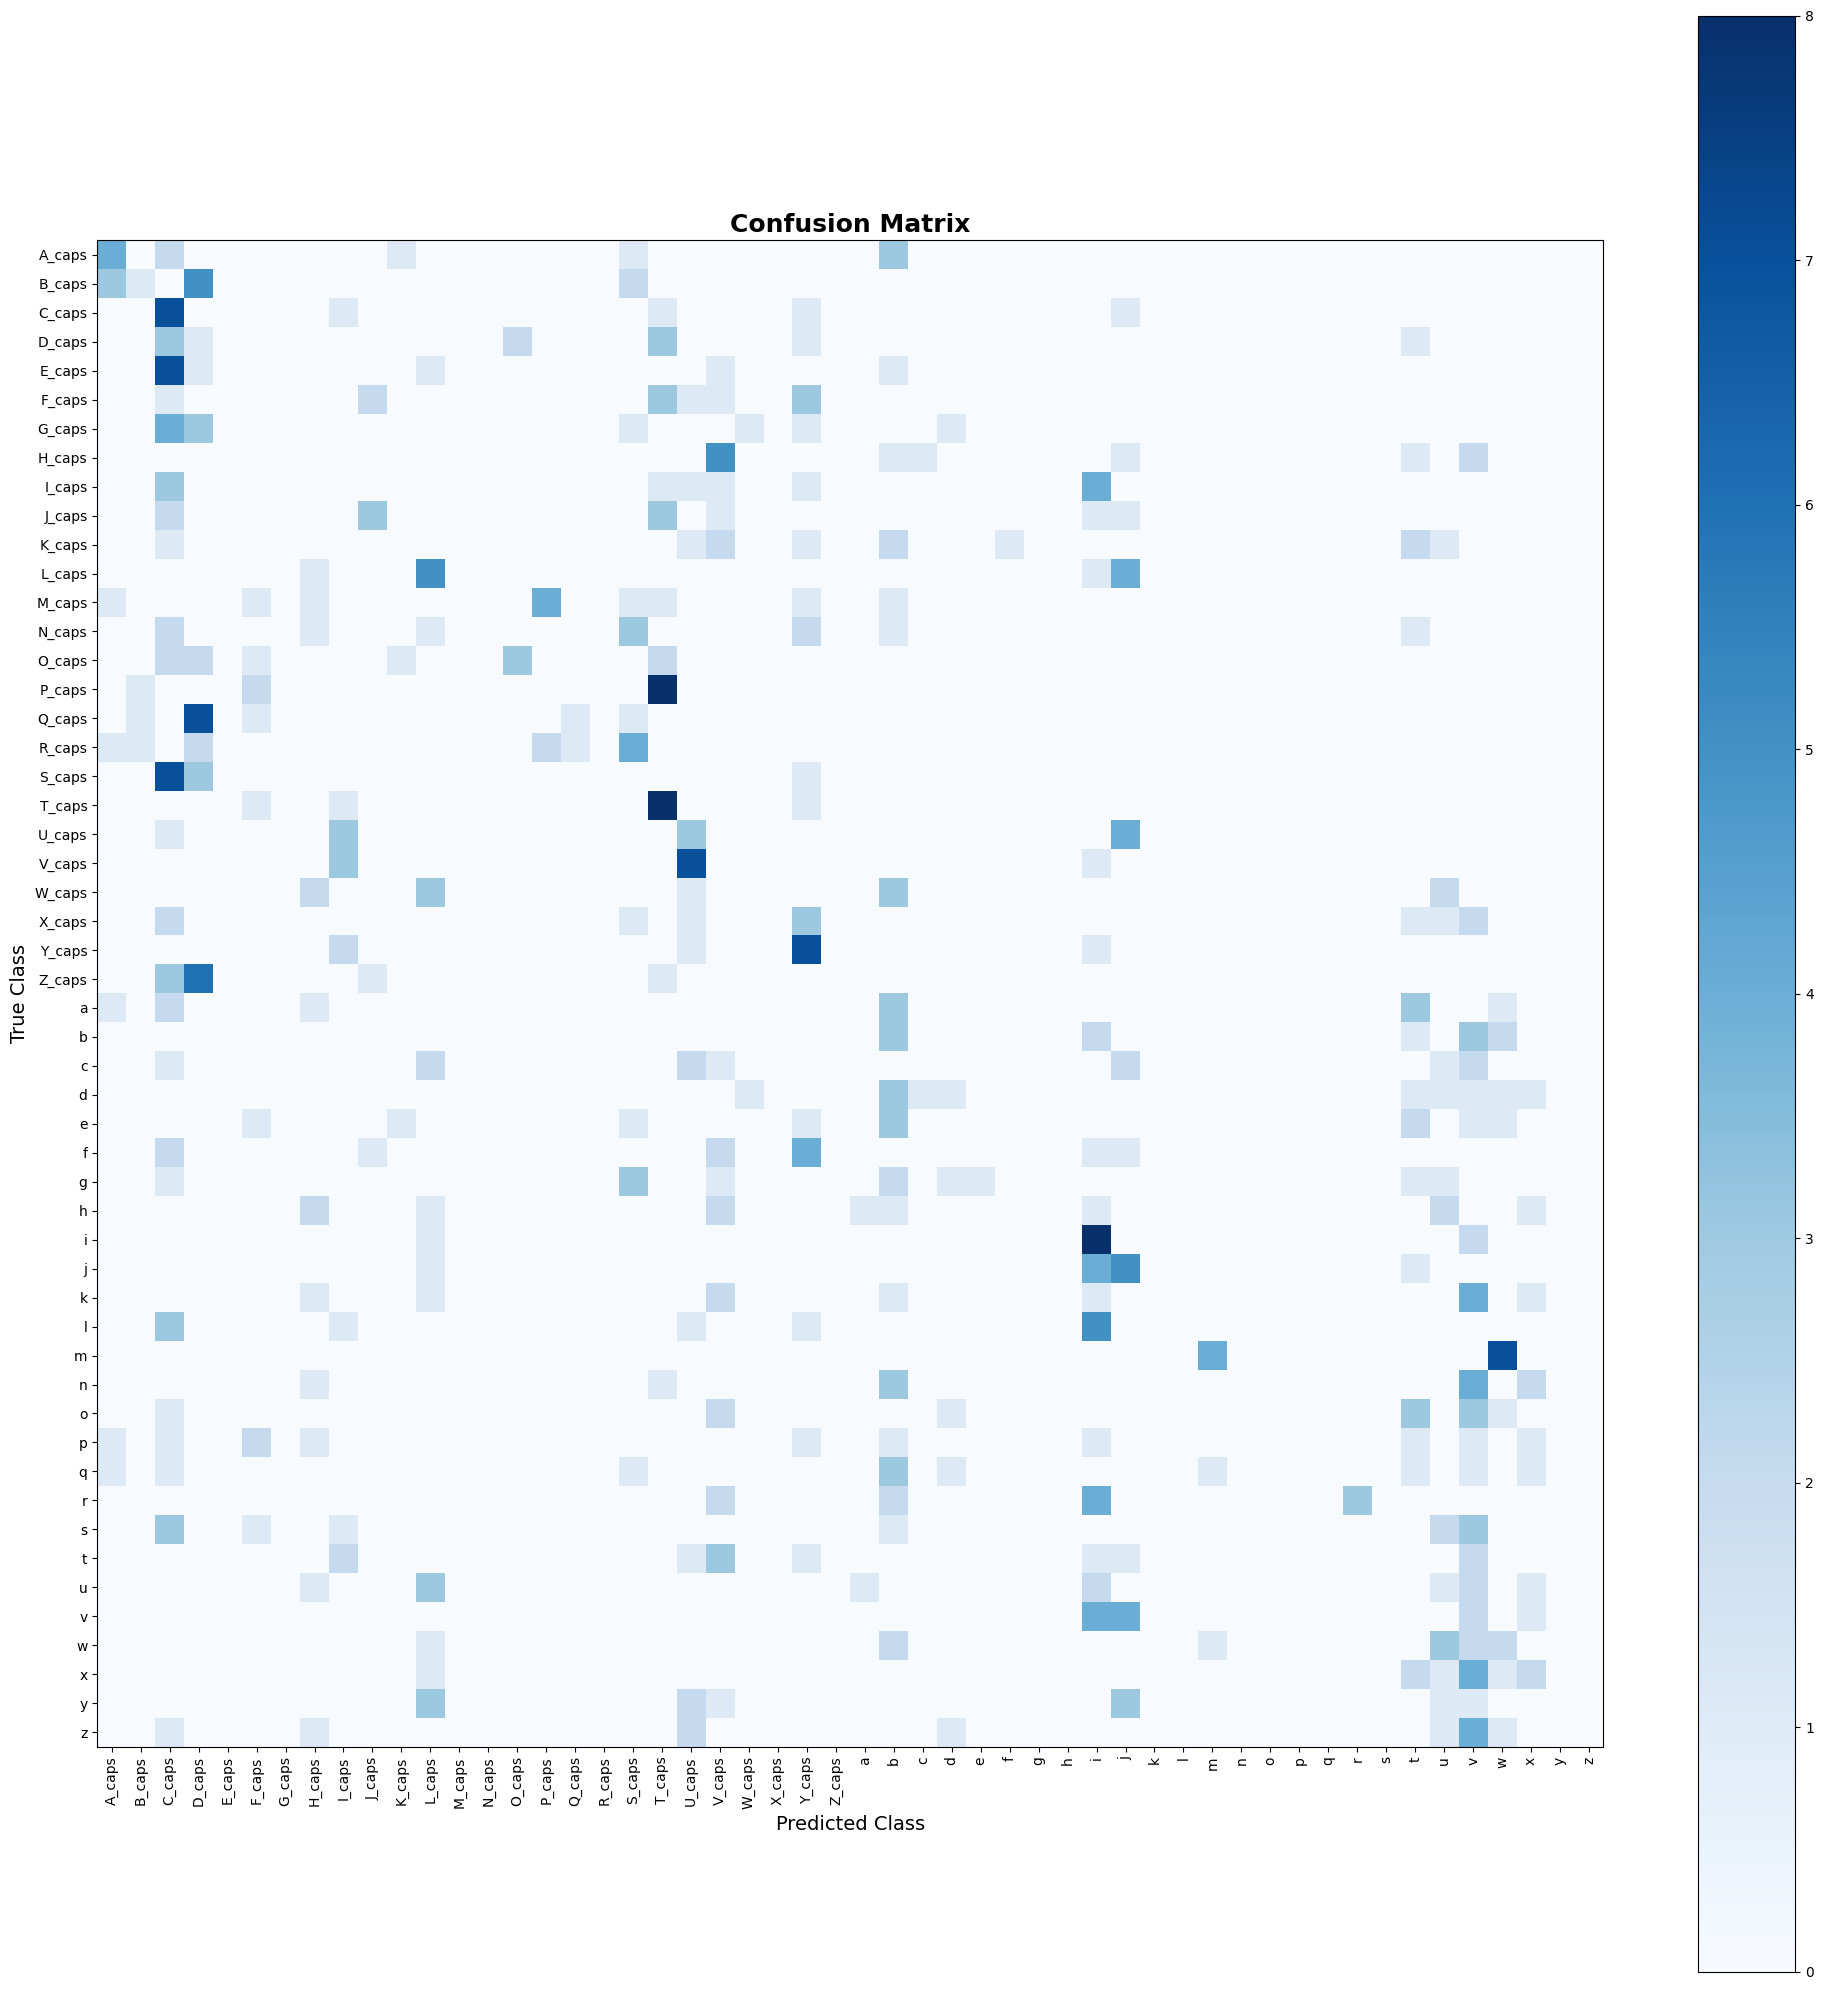

In [52]:
# ==========================================================
# Confusion Matrix
# ==========================================================

# Compute Confusion Matrix
cm = confusion_matrix(
    y_true=true_labels,
    y_pred=predicted_labels
)

# Create Figure
fig, ax = plt.subplots(figsize=(20, 20))

# Display Confusion Matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes_name
)

disp.plot(
    cmap="Blues",
    include_values=False,      # Recommended for 52 classes
    xticks_rotation=90,
    colorbar=True,
    ax=ax
)

ax.set_title(
    "Confusion Matrix",
    fontsize=18,
    fontweight="bold"
)

ax.set_xlabel("Predicted Class", fontsize=14)
ax.set_ylabel("True Class", fontsize=14)

plt.tight_layout()

plt.show()

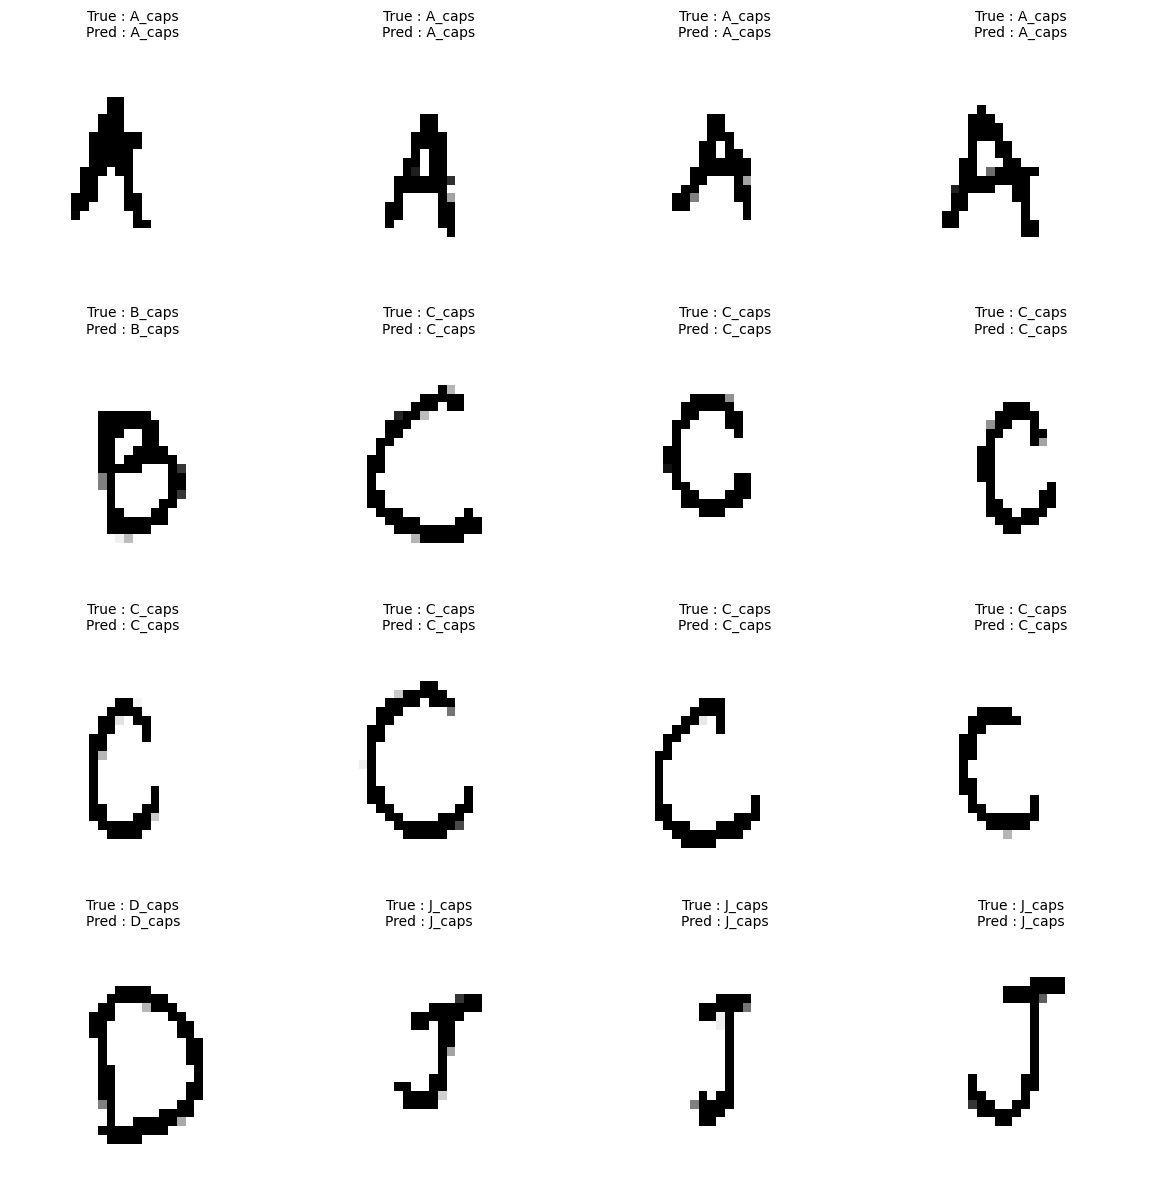

In [53]:
# ==========================================================
# Display Correct Predictions
# ==========================================================

# Collect all test images
test_images = np.concatenate(
    [images.numpy() for images, _ in test_dataset],
    axis=0
)

plt.figure(figsize=(12, 12))

count = 0

for i in range(len(test_images)):

    if predicted_labels[i] == true_labels[i]:

        plt.subplot(4, 4, count + 1)

        plt.imshow(
            test_images[i].squeeze(),
            cmap="gray"
        )

        plt.title(
            f"True : {classes_name[true_labels[i]]}\n"
            f"Pred : {classes_name[predicted_labels[i]]}",
            fontsize=10
        )

        plt.axis("off")

        count += 1

        if count == 16:
            break

plt.tight_layout()

plt.show()

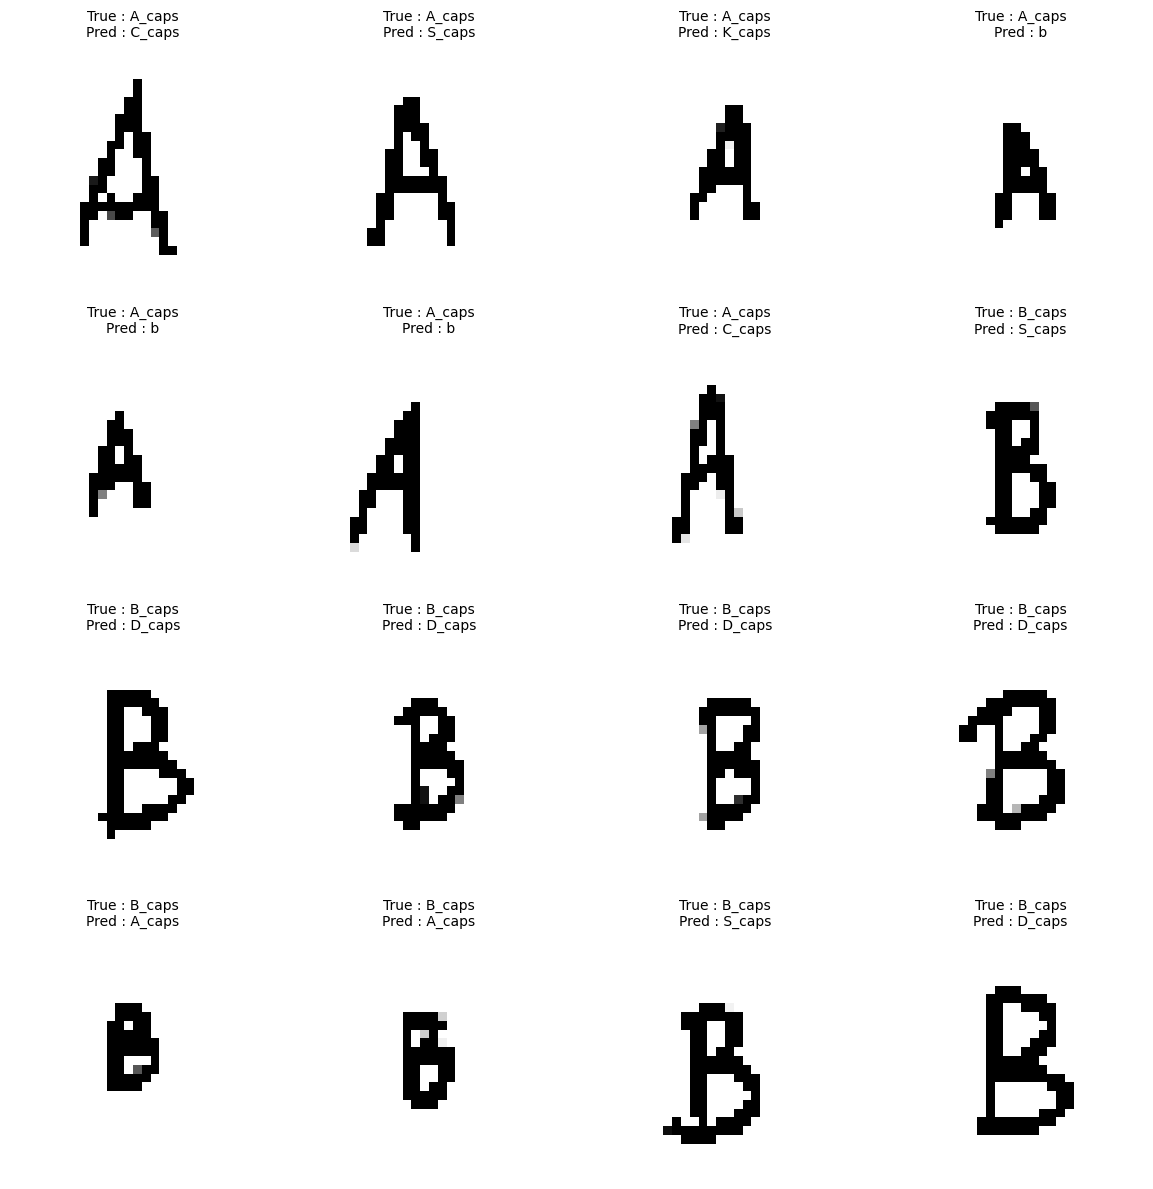

In [54]:
# ==========================================================
# Display Wrong Predictions
# ==========================================================

# Collect all test images
test_images = np.concatenate(
    [images.numpy() for images, _ in test_dataset],
    axis=0
)

plt.figure(figsize=(12, 12))

count = 0

for i in range(len(test_images)):

    if predicted_labels[i] != true_labels[i]:

        plt.subplot(4, 4, count + 1)

        plt.imshow(
            test_images[i].squeeze(),
            cmap="gray"
        )

        plt.title(
            f"True : {classes_name[true_labels[i]]}\n"
            f"Pred : {classes_name[predicted_labels[i]]}",
            fontsize=10
        )

        plt.axis("off")

        count += 1

        if count == 16:
            break

plt.tight_layout()

plt.show()

Top-5 Prediction Probabilities

Image 1
1. A_caps          13.90%
2. H_caps           5.27%
3. P_caps           4.20%
4. M_caps           3.63%
5. K_caps           3.62%
----------------------------------------------------------------------

Image 2
1. C_caps          10.53%
2. D_caps           6.65%
3. S_caps           6.02%
4. U_caps           5.88%
5. J_caps           5.74%
----------------------------------------------------------------------

Image 3
1. S_caps           8.87%
2. C_caps           6.77%
3. E_caps           5.37%
4. D_caps           4.71%
5. X_caps           4.64%
----------------------------------------------------------------------

Image 4
1. A_caps           5.97%
2. b                5.34%
3. p                4.25%
4. H_caps           4.23%
5. K_caps           3.82%
----------------------------------------------------------------------

Image 5
1. A_caps           5.85%
2. H_caps           5.07%
3. p                5.02%
4. b                5.02%
5. n            

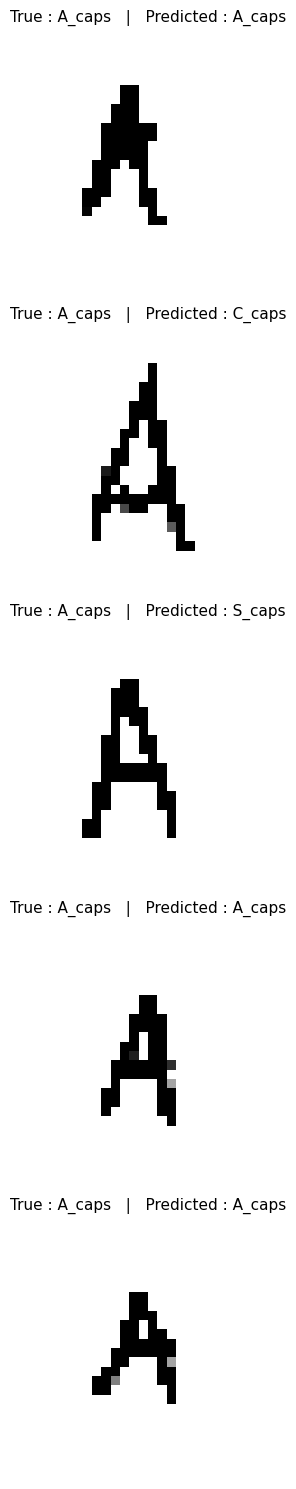

In [55]:
# ==========================================================
# Top-5 Prediction Probabilities
# ==========================================================

NUM_IMAGES = 5

print("=" * 70)
print("Top-5 Prediction Probabilities")
print("=" * 70)

plt.figure(figsize=(15, 3 * NUM_IMAGES))

for i in range(NUM_IMAGES):

    # Display Image
    plt.subplot(NUM_IMAGES, 1, i + 1)

    plt.imshow(test_images[i].squeeze(), cmap="gray")

    plt.title(
        f"True : {classes_name[true_labels[i]]}   |   "
        f"Predicted : {classes_name[predicted_labels[i]]}",
        fontsize=11
    )

    plt.axis("off")

    # Top-5 Predictions
    top5 = np.argsort(predictions[i])[-5:][::-1]

    print(f"\nImage {i + 1}")

    for rank, idx in enumerate(top5, start=1):

        print(
            f"{rank}. "
            f"{classes_name[idx]:<15}"
            f"{predictions[i][idx] * 100:6.2f}%"
        )

    print("-" * 70)

plt.tight_layout()

plt.show()

In [56]:
# ==========================================================
# Project Performance Summary
# ==========================================================

print("=" * 70)
print("Project Performance Summary")
print("=" * 70)

print(f"Dataset Classes        : {len(classes_name)}")
print(f"Input Image Size       : 28 × 28 × 1")
print(f"Training Epochs        : {len(history.history['loss'])}")
print(f"Final Test Accuracy    : {test_accuracy * 100:.2f}%")
print(f"Saved Model            : best_character_model.keras")

print("=" * 70)
print("Model Training and Evaluation Completed Successfully.")
print("=" * 70)

Project Performance Summary
Dataset Classes        : 52
Input Image Size       : 28 × 28 × 1
Training Epochs        : 36
Final Test Accuracy    : 12.94%
Saved Model            : best_character_model.keras
Model Training and Evaluation Completed Successfully.


Total Images Found : 5


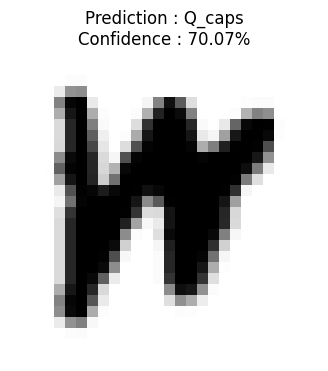

Image Name : sample_image1.png
Predicted Character : Q_caps
Confidence : 70.07%

Top-5 Predictions
----------------------------------------------------------------------
1. Q_caps          70.07%
2. B_caps          21.81%
3. R_caps           4.37%
4. M_caps           2.38%
5. g                0.61%


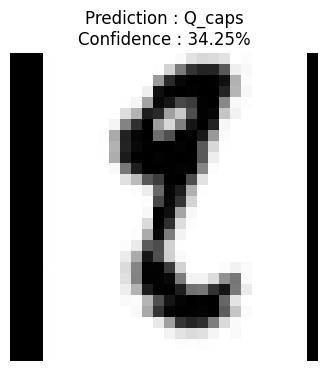

Image Name : sample_image2.jpg
Predicted Character : Q_caps
Confidence : 34.25%

Top-5 Predictions
----------------------------------------------------------------------
1. Q_caps          34.25%
2. B_caps          18.04%
3. D_caps          12.65%
4. R_caps           7.05%
5. Z_caps           6.15%


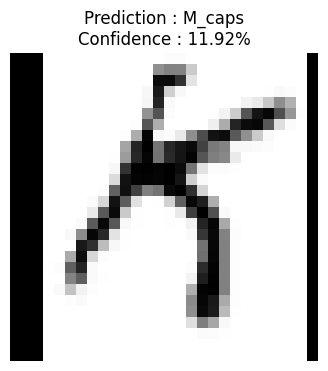

Image Name : sample_image3.jpg
Predicted Character : M_caps
Confidence : 11.92%

Top-5 Predictions
----------------------------------------------------------------------
1. M_caps          11.92%
2. P_caps          10.85%
3. B_caps           8.90%
4. R_caps           6.04%
5. Z_caps           5.73%


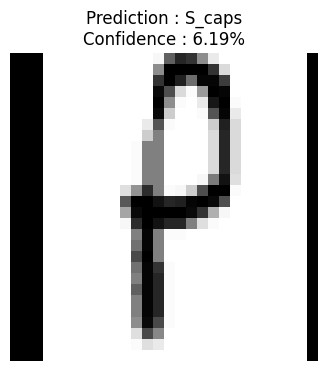

Image Name : sample_image4.png
Predicted Character : S_caps
Confidence : 6.19%

Top-5 Predictions
----------------------------------------------------------------------
1. S_caps           6.19%
2. Y_caps           5.91%
3. f                5.29%
4. O_caps           5.13%
5. C_caps           4.74%


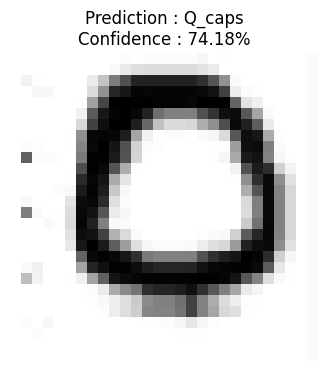

Image Name : sanple_image5.jpg
Predicted Character : Q_caps
Confidence : 74.18%

Top-5 Predictions
----------------------------------------------------------------------
1. Q_caps          74.18%
2. B_caps          10.26%
3. R_caps           4.00%
4. D_caps           2.95%
5. Z_caps           2.06%


In [57]:
# ==========================================================
# Custom Predict All Images in Folder
# ==========================================================

import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# ----------------------------------------------------------
# Folder Path
# ----------------------------------------------------------

IMAGE_FOLDER = "/kaggle/input/datasets/rahulkumar1822/images-file"

# ----------------------------------------------------------
# Get All Image Files
# ----------------------------------------------------------

image_paths = sorted(
    glob.glob(os.path.join(IMAGE_FOLDER, "*"))
)

print("=" * 70)
print(f"Total Images Found : {len(image_paths)}")
print("=" * 70)

# ----------------------------------------------------------
# Predict Each Image
# ----------------------------------------------------------

for image_path in image_paths:

    # Load Image
    image = tf.keras.utils.load_img(
        image_path,
        color_mode="grayscale",
        target_size=(28, 28)
    )

    # Convert to Array
    image_array = tf.keras.utils.img_to_array(image)

    # Normalize
    image_array = image_array.astype("float32") / 255.0

    # Add Batch Dimension
    image_array = np.expand_dims(image_array, axis=0)

    # Prediction
    prediction = model.predict(image_array, verbose=0)

    predicted_class = np.argmax(prediction[0])

    confidence = prediction[0][predicted_class]

    # Top-5 Predictions
    top5 = np.argsort(prediction[0])[-5:][::-1]

    # ------------------------------------------------------
    # Display Image
    # ------------------------------------------------------

    plt.figure(figsize=(4,4))

    plt.imshow(image_array[0].squeeze(), cmap="gray")

    plt.title(
        f"Prediction : {classes_name[predicted_class]}\n"
        f"Confidence : {confidence*100:.2f}%"
    )

    plt.axis("off")

    plt.show()

    # ------------------------------------------------------
    # Print Result
    # ------------------------------------------------------

    print("=" * 70)

    print(f"Image Name : {os.path.basename(image_path)}")

    print(f"Predicted Character : {classes_name[predicted_class]}")

    print(f"Confidence : {confidence*100:.2f}%")

    print("\nTop-5 Predictions")

    print("-" * 70)

    for rank, idx in enumerate(top5, start=1):

        print(
            f"{rank}. "
            f"{classes_name[idx]:<15}"
            f"{prediction[0][idx]*100:6.2f}%"
        )

    print("=" * 70)

In [58]:
# End